# Cell 1 — Project Introduction

# SmartSpend AI – Budget Recommendation System

**Objective:** The system analyzes a user's income, demographic information, and monthly expense categories and predicts a suitable **monthly spending budget** using an **XGBoost Regressor**.

The notebook also calculates:

- Total monthly expenses
- Savings
- Savings percentage
- Recommended monthly budget
- Financial health score
- Spending insights
- Dashboard-ready output

> ⚠️ **This model is trained using synthetic financial data and is intended as a prototype/academic project, not professional financial advice.**

**Workflow:** generate data → clean → explore → train pipeline (OneHotEncoder + XGBoost) → evaluate → save → predict for a new user → health score → insights → dashboard JSON.

# Cell 2 — Install Required Libraries

Installs every package used in this notebook. Run it once; you can skip it if the packages are already installed.

In [33]:
# !pip install pandas numpy matplotlib seaborn scikit-learn aaxgboost joblib

# Cell 3 — Import Libraries

Imports all libraries and fixes the random seed so results are **reproducible** (same data and same model every run).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


# Cell 4 — Generate Synthetic Dataset

We create **7,500 monthly records** (625 users × 12 months). Expenses are **not independent** — they depend on each other's drivers:

```text
Income + City Tier              → Rent
Income + Dependents             → Groceries
Income + Occupation + City Tier → Transport
Age + Dependents                → Healthcare
```

- `Eating_Out` and `Entertainment` behave like **discretionary** spending (each user has their own "spending personality").
- `Utilities` depends on income and dependents; `Education` is higher when there are dependents (or the user is a student).
- Random noise is added so the data is **not perfectly predictable**, and values are clipped to stay realistic (`Income > 0`, `expenses >= 0`).

In [3]:
rng = np.random.default_rng(RANDOM_STATE)

N_USERS = 625
N_MONTHS = 12            # 625 x 12 = 7,500 records
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

occupations = ["Student", "Salaried", "Self-Employed", "Freelancer", "Business", "Other"]
occupation_probs = [0.10, 0.45, 0.12, 0.10, 0.13, 0.10]
city_tiers = ["Tier_1", "Tier_2", "Tier_3"]
tier_probs = [0.35, 0.40, 0.25]

expense_categories = ["Rent", "Groceries", "Transport", "Eating_Out", "Entertainment",
                      "Utilities", "Healthcare", "Education", "Miscellaneous"]

# ---------- Step 1: one profile per user (these stay the same every month) ----------
users = pd.DataFrame({"User_ID": [f"U{i:04d}" for i in range(1, N_USERS + 1)]})
users["Occupation"] = rng.choice(occupations, size=N_USERS, p=occupation_probs)
users["City_Tier"] = rng.choice(city_tiers, size=N_USERS, p=tier_probs)

is_student = (users["Occupation"] == "Student").to_numpy()
users["Age"] = np.where(is_student,
                        rng.integers(18, 28, N_USERS),
                        rng.integers(22, 61, N_USERS))

# Older users tend to have more dependents; students have none
dep_lambda = np.clip(0.2 + 0.045 * (users["Age"].to_numpy() - 22), 0, 2.0)
dependents = np.clip(rng.poisson(dep_lambda), 0, 5)
users["Dependents"] = np.where(is_student, 0, dependents)

# Typical monthly income (Rs.) by occupation, adjusted by city tier
median_income = {"Student": 15000, "Salaried": 55000, "Self-Employed": 60000,
                 "Freelancer": 45000, "Business": 90000, "Other": 25000}
tier_income_mult = {"Tier_1": 1.25, "Tier_2": 1.00, "Tier_3": 0.85}
users["Base_Income"] = (users["Occupation"].map(median_income).to_numpy()
                        * users["City_Tier"].map(tier_income_mult).to_numpy()
                        * rng.lognormal(0, 0.30, N_USERS))

# Personal "spending personality": >1 = spends more on discretionary items
users["Tendency"] = rng.lognormal(0, 0.30, N_USERS)

# ---------- Step 2: repeat each user for 12 months ----------
df = users.loc[users.index.repeat(N_MONTHS)].reset_index(drop=True)
df["Month"] = np.tile(MONTHS, N_USERS)
n = len(df)

def noise(sigma):
    # random multiplier around 1.0 -> makes data realistic but not perfectly predictable
    return rng.lognormal(0, sigma, n)

# ---------- Step 3: monthly income (freelancers/business vary more month to month) ----------
volatility = {"Student": 0.05, "Salaried": 0.03, "Self-Employed": 0.12,
              "Freelancer": 0.20, "Business": 0.18, "Other": 0.10}
vol = df["Occupation"].map(volatility).to_numpy()
df["Income"] = (df["Base_Income"] * np.clip(rng.normal(1, vol), 0.5, 1.8)).clip(5000, 500000).round(0)

income = df["Income"].to_numpy()
age = df["Age"].to_numpy()
dep = df["Dependents"].to_numpy()
tend = df["Tendency"].to_numpy()
occ = df["Occupation"]
tier = df["City_Tier"]

# ---------- Step 4: expenses with realistic relationships ----------
# Rent  <- Income + City Tier (students share rooms / live in hostels)
rent_rate = tier.map({"Tier_1": 0.30, "Tier_2": 0.22, "Tier_3": 0.15}).to_numpy()
rent_occ = np.where(occ == "Student", 0.6, 1.0)
df["Rent"] = np.clip(income * rent_rate * rent_occ * noise(0.12), 1000, 0.50 * income)

# Groceries <- Income + Dependents (+ city price level)
groc_city = tier.map({"Tier_1": 1.10, "Tier_2": 1.00, "Tier_3": 0.90}).to_numpy()
df["Groceries"] = np.clip((2500 + 0.06 * income + 2200 * dep) * groc_city * noise(0.12),
                          1000, 0.35 * income)

# Transport <- Income + Occupation + City Tier
trans_occ = occ.map({"Student": 0.06, "Salaried": 0.07, "Self-Employed": 0.08,
                     "Freelancer": 0.06, "Business": 0.09, "Other": 0.07}).to_numpy()
trans_city = tier.map({"Tier_1": 1.15, "Tier_2": 1.00, "Tier_3": 0.85}).to_numpy()
df["Transport"] = np.clip(income * trans_occ * trans_city * noise(0.20), 300, 0.20 * income)

# Healthcare <- Age + Dependents (+ a little income)
df["Healthcare"] = np.clip((300 + 25 * age + 0.012 * income + 500 * dep) * noise(0.30),
                           0, 0.20 * income)

# Discretionary spending: depends on income and the user's personal tendency
eat_city = tier.map({"Tier_1": 1.15, "Tier_2": 1.00, "Tier_3": 0.85}).to_numpy()
df["Eating_Out"] = np.clip(income * 0.05 * tend * eat_city / (1 + 0.08 * dep) * noise(0.25),
                           0, 0.15 * income)
df["Entertainment"] = np.clip(income * 0.035 * tend / (1 + 0.10 * dep) * noise(0.30),
                              0, 0.12 * income)

# Utilities <- Income + Dependents (+ city)
util_city = tier.map({"Tier_1": 1.10, "Tier_2": 1.00, "Tier_3": 0.90}).to_numpy()
df["Utilities"] = np.clip((800 + 0.025 * income + 350 * dep) * util_city * noise(0.10),
                          300, 0.15 * income)

# Education: students pay fees; users with dependents spend more on children's education
edu_student = income * 0.07 * noise(0.30)
edu_dependents = np.where(rng.random(n) < 0.85, income * 0.025 * dep * noise(0.30), 0)
edu_other = np.where(rng.random(n) < 0.12, income * 0.02 * noise(0.30), 0)   # occasional courses
education = np.where(occ == "Student", edu_student,
                     np.where(dep > 0, edu_dependents, edu_other))
df["Education"] = np.clip(education, 0, 0.25 * income)

# Miscellaneous: small, noisy
df["Miscellaneous"] = np.clip(300 + income * 0.03 * noise(0.40), 0, 0.12 * income)

# ---------- Step 5: safety check - nobody spends more than 120% of income ----------
total_raw = df[expense_categories].sum(axis=1).to_numpy()
scale = np.minimum(1.0, 1.2 * income / total_raw)
for col in expense_categories:
    df[col] = (df[col] * scale).round(0)

print("Synthetic base data generated:", df.shape)

Synthetic base data generated: (7500, 18)


# Cell 5 — Create Recommended Budget Target

First we calculate `Total_Expenses`, `Savings` and `Savings_Percentage`.

Then we create the ML target, **`Recommended_Budget`**, which is **not** just `Total_Expenses`:

```text
Income → Desired Savings Rate → Target Savings → Affordable Spending → Recommended Budget
```

The desired savings rate (10–30%) is influenced by **income** (higher income can save more), **dependents** (more responsibilities → lower rate), **essential expenses** (high essentials → less room to save) and **discretionary spending** (overspending on extras → suggest saving more). Random variation is added. The budget is never below essential costs and never above income.

`Total_Expenses` and `Savings` are **not** used to build the target, which avoids direct leakage.

In [4]:
# --- Derived financial columns ---
df["Total_Expenses"] = df[expense_categories].sum(axis=1)
df["Savings"] = df["Income"] - df["Total_Expenses"]
df["Savings_Percentage"] = ((df["Savings"] / df["Income"]) * 100).round(2)

# --- Build the desired savings rate ---
essential = df["Rent"] + df["Groceries"] + df["Utilities"] + df["Healthcare"] + df["Transport"]
essential_ratio = essential / df["Income"]
discretionary_ratio = (df["Eating_Out"] + df["Entertainment"]) / df["Income"]

desired_rate = 0.12                                                    # base: 12%
desired_rate = desired_rate + 0.10 * np.clip((df["Income"] - 20000) / 100000, 0, 1)   # higher income -> save more
desired_rate = desired_rate - 0.012 * df["Dependents"]                 # dependents -> lower rate
desired_rate = desired_rate - 0.10 * np.clip(essential_ratio - 0.45, 0, 0.40)         # heavy essentials -> lower rate
desired_rate = desired_rate + 0.40 * np.clip(discretionary_ratio - 0.08, 0, 0.10)     # overspending on extras -> higher rate
desired_rate = desired_rate + rng.normal(0, 0.02, len(df))             # realistic random variation
desired_rate = np.clip(desired_rate, 0.10, 0.30)                       # keep within 10%-30%

# --- Income -> Target Savings -> Affordable Spending ---
target_savings = df["Income"] * desired_rate
budget = df["Income"] - target_savings

# Budget can never be less than essential costs, and can never exceed income
budget = np.maximum(budget, essential)
budget = np.minimum(budget, df["Income"])
df["Recommended_Budget"] = budget.round(0)

# --- Final column order ---
final_columns = ["User_ID", "Month", "Income", "Age", "Dependents", "Occupation", "City_Tier"] \
                + expense_categories \
                + ["Total_Expenses", "Savings", "Savings_Percentage", "Recommended_Budget"]
df = df[final_columns]

assert (df["Income"] > 0).all()
assert (df[expense_categories] >= 0).all().all()
assert (df["Recommended_Budget"] > 0).all()
assert (df["Recommended_Budget"] <= df["Income"]).all()
print("Target created. All sanity checks passed.")

Target created. All sanity checks passed.


# Cell 6 — Save Dataset to CSV

Saves the dataset as `smartspend_synthetic_data.csv` (created automatically when you run the notebook) and shows a quick overview.

In [5]:
df.to_csv("smartspend_synthetic_data.csv", index=False)
print("Dataset saved to smartspend_synthetic_data.csv\n")

print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumns:")
print(df.columns)
print("\nStatistical summary:")
display(df.describe())

Dataset saved to smartspend_synthetic_data.csv

Shape: (7500, 20)

First 5 rows:


,User_ID,Month,Income,Age,Dependents,Occupation,City_Tier,Rent,Groceries,Transport,Eating_Out,Entertainment,Utilities,Healthcare,Education,Miscellaneous,Total_Expenses,Savings,Savings_Percentage,Recommended_Budget
0,U0001,Jan,95552.0,56,2,Business,Tier_2,19838.0,14207.0,7863.0,2834.0,2548.0,3428.0,1727.0,6779.0,1608.0,60832.0,34720.0,36.34,79451.0
1,U0001,Feb,78689.0,56,2,Business,Tier_2,14767.0,12362.0,10705.0,2295.0,1891.0,3186.0,3629.0,1963.0,2398.0,53196.0,25493.0,32.40,64698.0
2,U0001,Mar,83948.0,56,2,Business,Tier_2,20273.0,12158.0,6557.0,1410.0,1227.0,3379.0,3964.0,0.0,1932.0,50900.0,33048.0,39.37,71921.0
3,U0001,Apr,73990.0,56,2,Business,Tier_2,18973.0,10441.0,8182.0,2735.0,1222.0,3622.0,3521.0,4430.0,1769.0,54895.0,19095.0,25.81,64377.0
4,U0001,May,68427.0,56,2,Business,Tier_2,15005.0,12357.0,8238.0,2050.0,1347.0,3856.0,2922.0,4578.0,1478.0,51831.0,16596.0,24.25,61584.0



Columns:
Index(['User_ID', 'Month', 'Income', 'Age', 'Dependents', 'Occupation',
       'City_Tier', 'Rent', 'Groceries', 'Transport', 'Eating_Out',
       'Entertainment', 'Utilities', 'Healthcare', 'Education',
       'Miscellaneous', 'Total_Expenses', 'Savings', 'Savings_Percentage',
       'Recommended_Budget'],
      dtype='str')

Statistical summary:


,Income,Age,Dependents,Rent,Groceries,Transport,Eating_Out,Entertainment,Utilities,Healthcare,Education,Miscellaneous,Total_Expenses,Savings,Savings_Percentage,Recommended_Budget
count,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.000000,7500.00000,7500.000000,7500.000000,7500.000000,7500.000000
mean,58931.830933,39.700800,0.966400,14104.737733,8314.139600,4677.062667,3027.965867,2055.851867,2667.976667,2580.749333,1504.192133,2205.33640,41138.012267,17793.818667,28.095051,49664.613867
std,31964.084391,12.100463,1.086935,9804.453157,3631.279519,3432.065006,2342.160988,1566.805704,1050.690813,1247.579831,2132.318327,1370.79678,22075.223086,13558.901753,13.926862,25185.103813
min,8759.000000,18.000000,0.000000,1000.000000,2127.000000,300.000000,180.000000,125.000000,710.000000,456.000000,0.000000,428.00000,7305.000000,-11538.000000,-20.010000,7883.000000
25%,37721.500000,29.000000,0.000000,6977.000000,5656.750000,2414.000000,1470.750000,1008.000000,1957.000000,1681.750000,0.000000,1288.00000,26153.000000,7900.500000,20.200000,33167.750000
50%,54150.500000,39.000000,1.000000,12193.000000,7897.000000,3895.000000,2392.000000,1646.000000,2549.000000,2377.500000,1002.000000,1895.00000,37544.000000,15990.000000,29.450000,46742.500000
75%,74763.500000,51.000000,2.000000,18905.750000,10300.000000,5956.250000,3897.000000,2631.500000,3238.000000,3239.000000,2113.250000,2739.00000,52295.000000,24832.500000,38.112500,62783.000000
max,286426.000000,60.000000,5.000000,77721.000000,38984.000000,33444.000000,30854.000000,20567.000000,10231.000000,12578.000000,37432.000000,15674.00000,196788.000000,133468.000000,60.560000,238164.000000


# Cell 7 — Load Dataset

Loads the CSV again, exactly as you would do in a real project where the data already exists in a file.

In [6]:
df = pd.read_csv("smartspend_synthetic_data.csv")
df.head()

,User_ID,Month,Income,Age,Dependents,Occupation,City_Tier,Rent,Groceries,Transport,Eating_Out,Entertainment,Utilities,Healthcare,Education,Miscellaneous,Total_Expenses,Savings,Savings_Percentage,Recommended_Budget
0,U0001,Jan,95552.0,56,2,Business,Tier_2,19838.0,14207.0,7863.0,2834.0,2548.0,3428.0,1727.0,6779.0,1608.0,60832.0,34720.0,36.34,79451.0
1,U0001,Feb,78689.0,56,2,Business,Tier_2,14767.0,12362.0,10705.0,2295.0,1891.0,3186.0,3629.0,1963.0,2398.0,53196.0,25493.0,32.40,64698.0
2,U0001,Mar,83948.0,56,2,Business,Tier_2,20273.0,12158.0,6557.0,1410.0,1227.0,3379.0,3964.0,0.0,1932.0,50900.0,33048.0,39.37,71921.0
3,U0001,Apr,73990.0,56,2,Business,Tier_2,18973.0,10441.0,8182.0,2735.0,1222.0,3622.0,3521.0,4430.0,1769.0,54895.0,19095.0,25.81,64377.0
4,U0001,May,68427.0,56,2,Business,Tier_2,15005.0,12357.0,8238.0,2050.0,1347.0,3856.0,2922.0,4578.0,1478.0,51831.0,16596.0,24.25,61584.0


# Cell 8 — Data Cleaning

We check data quality before training:

| Check | Why it matters |
|---|---|
| Missing values | Empty cells can break training |
| Duplicates | Repeated rows can bias the model |
| Negative expenses | Spending cannot be below zero |
| Invalid income | Income must be greater than zero |
| Data types | Numbers must be numeric, categories must be text |

Valid data is **not** deleted unnecessarily. Rows are removed only if a problem is actually found.

In [7]:
print("=== Dataset info (column types and non-null counts) ===")
df.info()

print("\n=== Missing values per column ===")
print(df.isnull().sum())

print("\n=== Duplicate rows ===")
n_duplicates = df.duplicated().sum()
print(n_duplicates)

print("\n=== Negative expenses ===")
n_negative = (df[expense_categories] < 0).any(axis=1).sum()
print(n_negative)

print("\n=== Invalid income (<= 0) ===")
n_bad_income = (df["Income"] <= 0).sum()
print(n_bad_income)

print("\n=== Data type check ===")
numeric_columns = ["Income", "Age", "Dependents"] + expense_categories + \
                  ["Total_Expenses", "Savings", "Savings_Percentage", "Recommended_Budget"]
wrong_types = [c for c in numeric_columns if not pd.api.types.is_numeric_dtype(df[c])]
print("Columns with wrong data type:", wrong_types if wrong_types else "None")

print("\n=== Category values ===")
print("Occupation:", sorted(df["Occupation"].unique()))
print("City_Tier :", sorted(df["City_Tier"].unique()))

# --- Clean only if a problem was found ---
if n_duplicates > 0:
    df = df.drop_duplicates()
if n_negative > 0 or n_bad_income > 0:
    df = df[(df["Income"] > 0) & ((df[expense_categories] >= 0).all(axis=1))]
df = df.dropna().reset_index(drop=True)

print("\nCleaning finished. Final shape:", df.shape)

=== Dataset info (column types and non-null counts) ===
<class 'pandas.DataFrame'>
RangeIndex: 7500 entries, 0 to 7499
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   User_ID             7500 non-null   str    
 1   Month               7500 non-null   str    
 2   Income              7500 non-null   float64
 3   Age                 7500 non-null   int64  
 4   Dependents          7500 non-null   int64  
 5   Occupation          7500 non-null   str    
 6   City_Tier           7500 non-null   str    
 7   Rent                7500 non-null   float64
 8   Groceries           7500 non-null   float64
 9   Transport           7500 non-null   float64
 10  Eating_Out          7500 non-null   float64
 11  Entertainment       7500 non-null   float64
 12  Utilities           7500 non-null   float64
 13  Healthcare          7500 non-null   float64
 14  Education           7500 non-null   float64
 15  Miscellane

# Cell 9 — Exploratory Data Analysis

Simple histograms to understand the shape of our key money columns.

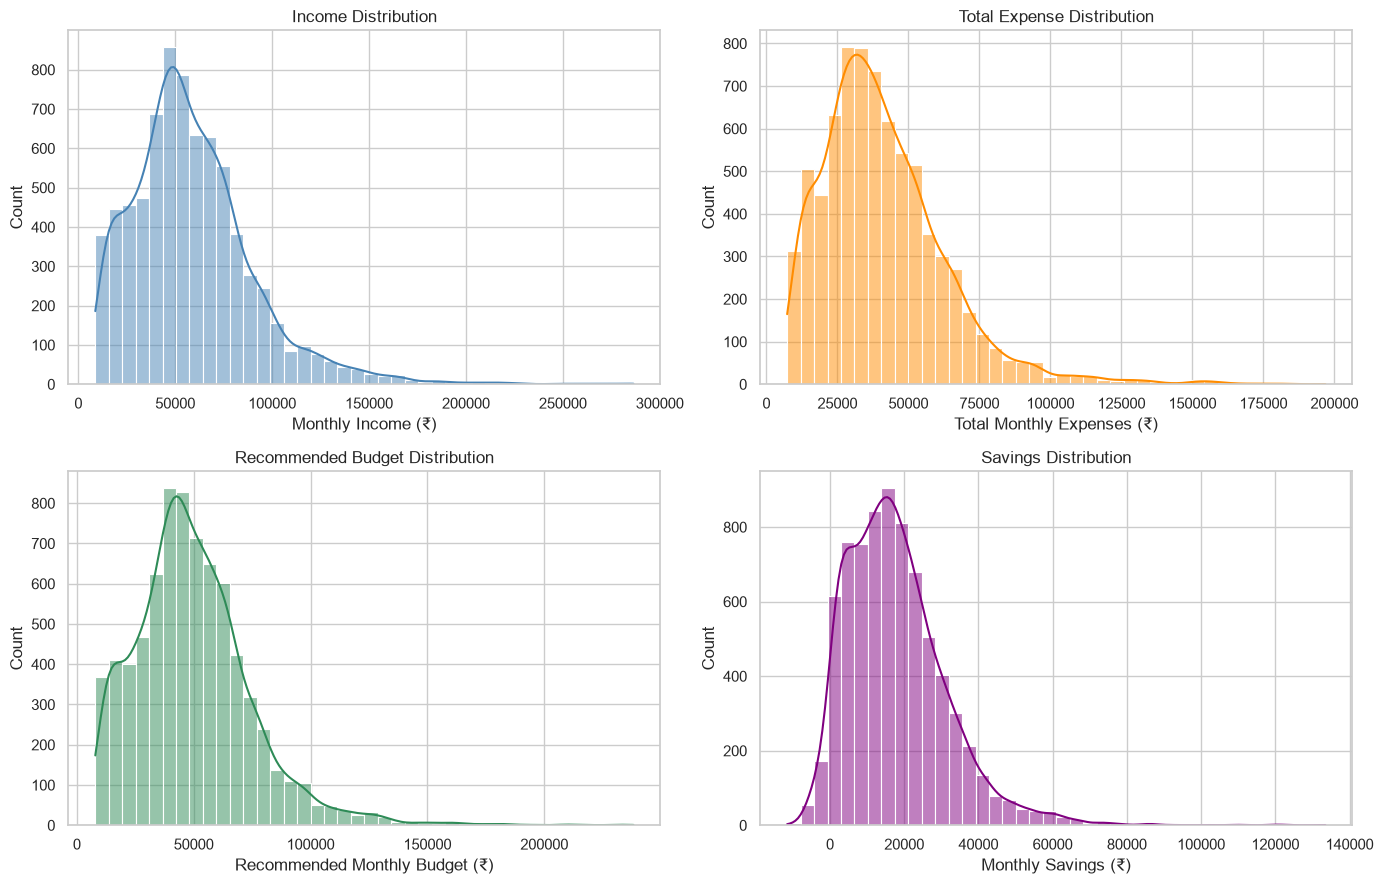

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df["Income"], bins=40, kde=True, color="steelblue", ax=axes[0, 0])
axes[0, 0].set_title("Income Distribution")
axes[0, 0].set_xlabel("Monthly Income (₹)")

sns.histplot(df["Total_Expenses"], bins=40, kde=True, color="darkorange", ax=axes[0, 1])
axes[0, 1].set_title("Total Expense Distribution")
axes[0, 1].set_xlabel("Total Monthly Expenses (₹)")

sns.histplot(df["Recommended_Budget"], bins=40, kde=True, color="seagreen", ax=axes[1, 0])
axes[1, 0].set_title("Recommended Budget Distribution")
axes[1, 0].set_xlabel("Recommended Monthly Budget (₹)")

sns.histplot(df["Savings"], bins=40, kde=True, color="purple", ax=axes[1, 1])
axes[1, 1].set_title("Savings Distribution")
axes[1, 1].set_xlabel("Monthly Savings (₹)")

plt.tight_layout()
plt.show()

# Cell 10 — Category Spending Analysis

Shows **where the money goes on average** across all records.

Rent             14105.0
Groceries         8314.0
Transport         4677.0
Eating_Out        3028.0
Utilities         2668.0
Healthcare        2581.0
Miscellaneous     2205.0
Entertainment     2056.0
Education         1504.0
dtype: float64


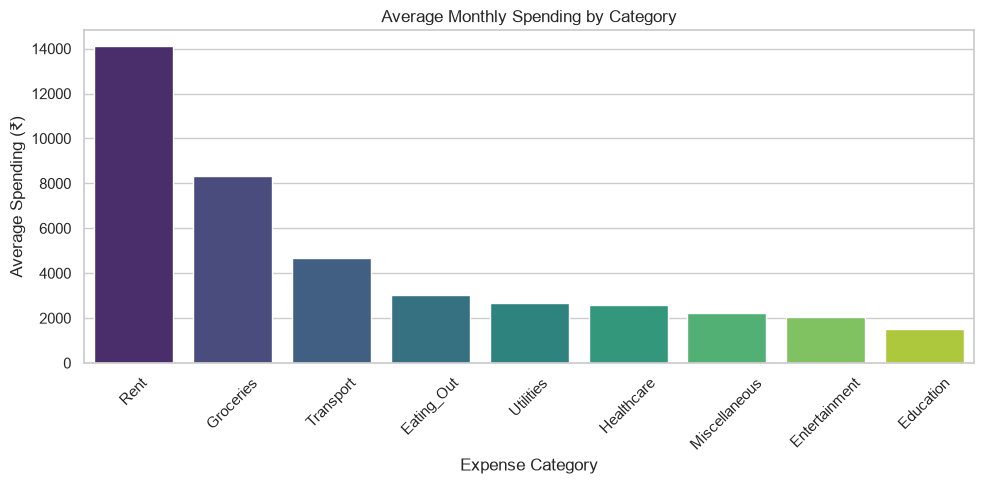

In [9]:
expense_categories = [
    "Rent",
    "Groceries",
    "Transport",
    "Eating_Out",
    "Entertainment",
    "Utilities",
    "Healthcare",
    "Education",
    "Miscellaneous"
]

avg_spending = df[expense_categories].mean().sort_values(ascending=False)
print(avg_spending.round(0))

plt.figure(figsize=(10, 5))
sns.barplot(x=avg_spending.index, y=avg_spending.values, hue=avg_spending.index,
            palette="viridis", legend=False)
plt.title("Average Monthly Spending by Category")
plt.xlabel("Expense Category")
plt.ylabel("Average Spending (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Cell 11 — Correlation Analysis

**Correlation** tells us how strongly two numbers move together, from **-1 to +1**:

- **Close to +1** → when one goes up, the other usually goes up too (e.g., Income and Rent).
- **Close to 0** → no clear relationship.
- **Close to -1** → when one goes up, the other goes down.

Correlation shows a *relationship*, not that one thing *causes* the other.

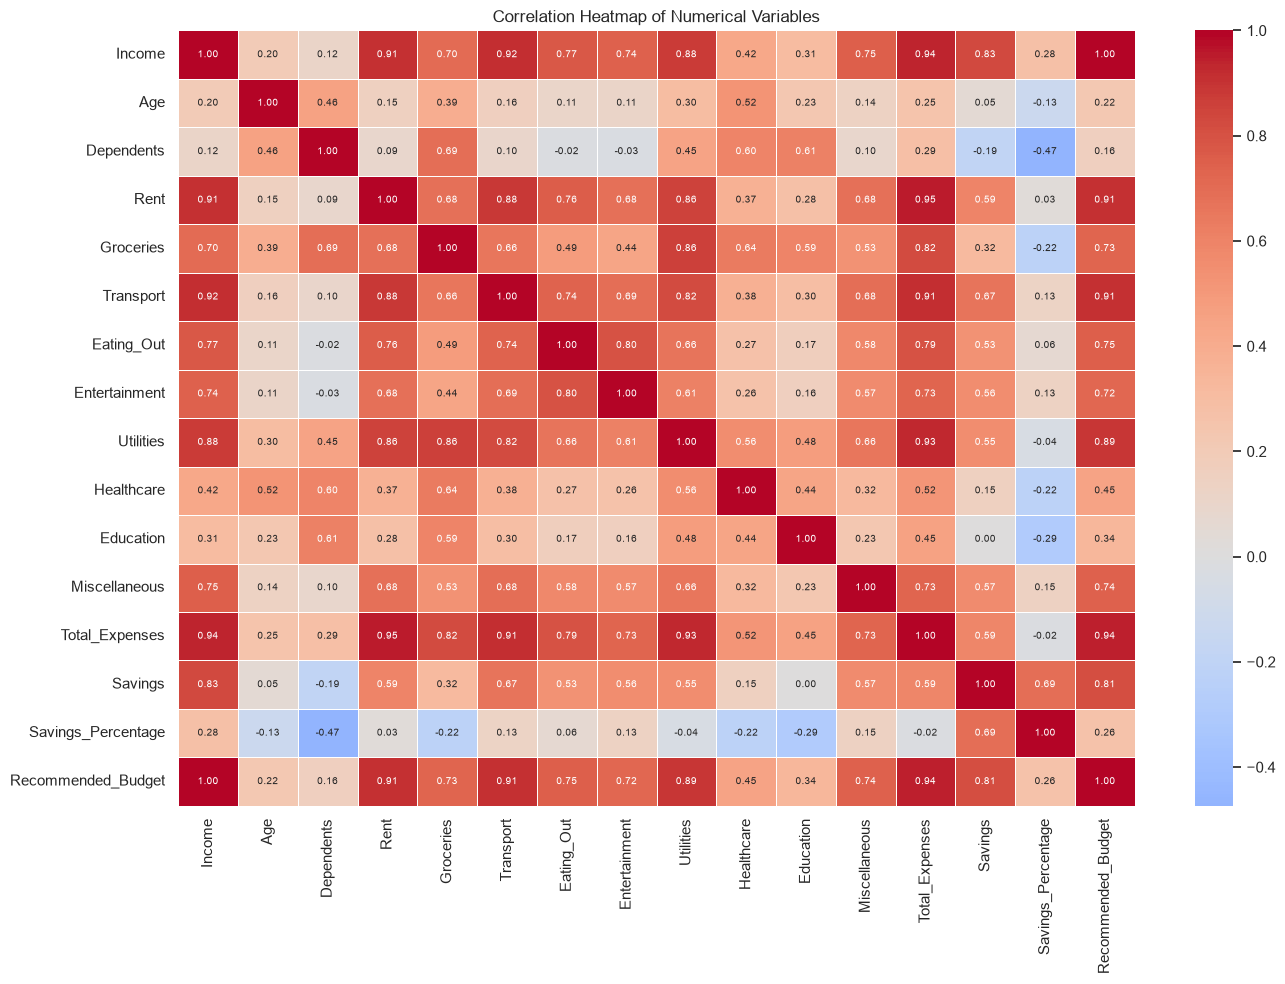

In [10]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 7}, linewidths=0.5)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

# Cell 12 — Select Model Features

- **Target (`y`)** = `Recommended_Budget` — the value we want to predict.
- **Features (`X`)** = the information a user would enter in the app.

`Total_Expenses`, `Savings` and `Savings_Percentage` are **excluded** to reduce target leakage: they are derived directly from financial variables the model already receives, and may encode information closely related to the synthetic target-generation process.

In [11]:
features = [
    "Income",
    "Age",
    "Dependents",
    "Occupation",
    "City_Tier",
    "Rent",
    "Groceries",
    "Transport",
    "Eating_Out",
    "Entertainment",
    "Utilities",
    "Healthcare",
    "Education",
    "Miscellaneous"
]

target = "Recommended_Budget"

X = df[features]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7500, 14)
y shape: (7500,)


# Cell 13 — Train/Test Split

80% of the data trains the model; the remaining 20% is kept **unseen** to test how well the model generalizes.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape :", y_test.shape)

X_train shape: (6000, 14)
X_test shape : (1500, 14)
y_train shape: (6000,)
y_test shape : (1500,)


# Cell 14 — Numerical and Categorical Features

Splits the feature list into numbers and text categories, because they are preprocessed differently.

In [13]:
numerical_features = [
    "Income",
    "Age",
    "Dependents",
    "Rent",
    "Groceries",
    "Transport",
    "Eating_Out",
    "Entertainment",
    "Utilities",
    "Healthcare",
    "Education",
    "Miscellaneous"
]

categorical_features = [
    "Occupation",
    "City_Tier"
]

print("Numerical features :", len(numerical_features))
print("Categorical features:", categorical_features)

Numerical features : 12
Categorical features: ['Occupation', 'City_Tier']


# Cell 15 — Preprocessing

XGBoost needs **numerical input**, so `Occupation` and `City_Tier` are converted using **One-Hot Encoding**. Example: `City_Tier = Tier_2` becomes `City_Tier_Tier_1 = 0`, `City_Tier_Tier_2 = 1`, `City_Tier_Tier_3 = 0`.

- `handle_unknown="ignore"` → an unseen category won't crash prediction.
- Numerical columns pass through unchanged (tree models don't need scaling).
- We do **not** encode categories manually; the pipeline does it automatically.

In [14]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created.")

Preprocessor created.


# Cell 16 — XGBoost Model

**XGBoost** builds many small decision trees, where each new tree fixes the mistakes of the previous ones.

- `n_estimators=300` → number of boosting trees.
- `learning_rate=0.05` → how much each tree contributes (smaller = slower but safer learning).
- `max_depth=5` → maximum complexity of each tree.
- `random_state=42` → reproducibility.

In [15]:
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    random_state=42,
    objective="reg:squarederror"
)

print("XGBoost model created.")

XGBoost model created.


# Cell 17 — Complete Pipeline

A **Pipeline** chains preprocessing and the model, so raw user data goes in and a prediction comes out. Saving the pipeline later stores both together.

In [16]:
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", xgb_model)
])

model_pipeline.fit(X_train, y_train)

print("Model training completed successfully.")

Model training completed successfully.


# Cell 18 — Prediction on Test Data

Predicts the budget for the 20% test rows the model has never seen.

In [17]:
y_pred = model_pipeline.predict(X_test)
print("Predictions generated for", len(y_pred), "test records.")

Predictions generated for 1500 test records.


# Cell 19 — Model Evaluation

- **MAE** (Mean Absolute Error): on average, how many rupees the prediction is off. Lower is better.
- **RMSE** (Root Mean Squared Error): like MAE but punishes big mistakes more. Lower is better.
- **R² Score**: how much of the variation in budgets the model explains (1.0 = perfect, 0 = no better than guessing the average).

> ⚠️ **A high R² on this dataset does NOT prove the model will achieve the same accuracy on real-world financial data**, because the model is trained and evaluated on synthetically generated data.

In [18]:
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE      : ₹{mae:,.2f}")
print(f"RMSE     : ₹{rmse:,.2f}")
print(f"R² Score : {r2:.4f}")
print()
print("Note: a high R² here does NOT guarantee the same accuracy on real-world data,")
print("because this model was trained and tested on synthetic data.")

MAE      : ₹975.87
RMSE     : ₹1,549.91
R² Score : 0.9957

Note: a high R² here does NOT guarantee the same accuracy on real-world data,
because this model was trained and tested on synthetic data.


# Cell 20 — Actual vs Predicted Results

A side-by-side table of the true budget and the model's prediction for 15 test records.

In [19]:
results = pd.DataFrame({
    "Actual_Budget": y_test.values,
    "Predicted_Budget": y_pred
})

results["Difference"] = (
    results["Actual_Budget"] -
    results["Predicted_Budget"]
).abs()

results.head(15)

,Actual_Budget,Predicted_Budget,Difference
0,63969.0,63395.476562,573.523438
1,60137.0,61253.160156,1116.160156
2,38148.0,37569.792969,578.207031
3,39973.0,40685.941406,712.941406
4,67718.0,65736.359375,1981.640625
5,53065.0,52294.757812,770.242188
6,63992.0,62864.554688,1127.445312
7,65706.0,67141.875000,1435.875000
8,27287.0,27799.060547,512.060547
9,41145.0,40772.562500,372.437500


# Cell 21 — Actual vs Predicted Plot

Each dot is one test record. The red dashed line is **perfect prediction** — the closer the dots are to it, the better.

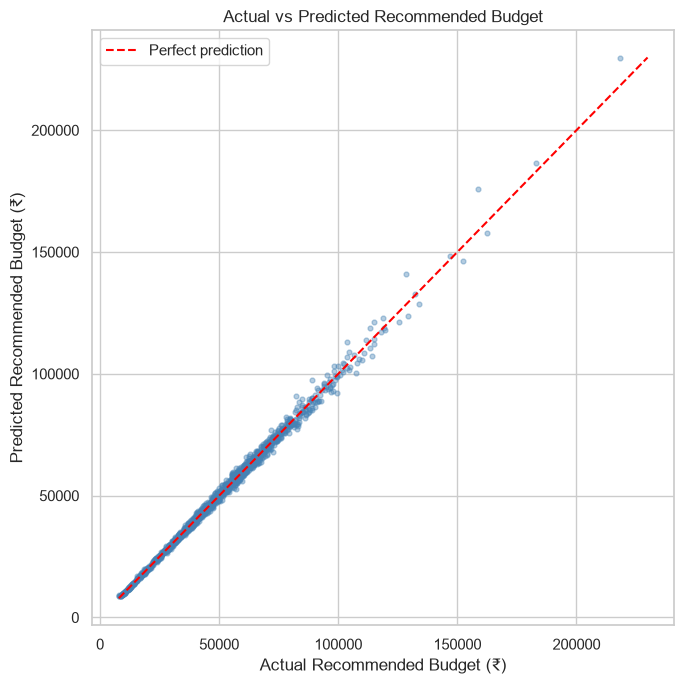

In [20]:
plt.figure(figsize=(7, 7))
plt.scatter(results["Actual_Budget"], results["Predicted_Budget"], alpha=0.4, s=12, color="steelblue")

low = min(results["Actual_Budget"].min(), results["Predicted_Budget"].min())
high = max(results["Actual_Budget"].max(), results["Predicted_Budget"].max())
plt.plot([low, high], [low, high], color="red", linestyle="--", label="Perfect prediction")

plt.title("Actual vs Predicted Recommended Budget")
plt.xlabel("Actual Recommended Budget (₹)")
plt.ylabel("Predicted Recommended Budget (₹)")
plt.legend()
plt.tight_layout()
plt.show()

# Cell 22 — Feature Importance

Shows which inputs the model relied on most. After one-hot encoding, the model sees names like `Occupation_Salaried`, so we rebuild the full list of names in the **same order** as the preprocessor output (encoded categories first, then numerical columns).

,Feature,Importance
0,Income,0.969129
1,Utilities,0.008316
2,City_Tier_Tier_1,0.005239
3,Groceries,0.004064
4,Dependents,0.002815
5,Rent,0.002398
6,Healthcare,0.001204
7,Transport,0.001116
8,Eating_Out,0.001105
9,Education,0.000816


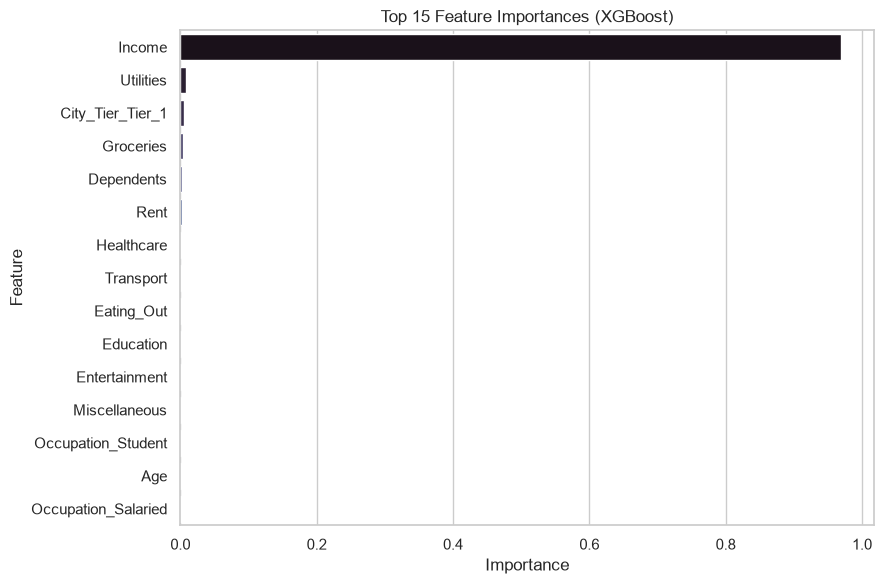

In [21]:
fitted_preprocessor = model_pipeline.named_steps["preprocessor"]
fitted_encoder = fitted_preprocessor.named_transformers_["cat"]

encoded_names = list(fitted_encoder.get_feature_names_out(categorical_features))
all_feature_names = encoded_names + numerical_features

importances = model_pipeline.named_steps["model"].feature_importances_
assert len(all_feature_names) == len(importances)

importance_df = (
    pd.DataFrame({"Feature": all_feature_names, "Importance": importances})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

top_features = importance_df.head(15)
display(top_features)

plt.figure(figsize=(9, 6))
sns.barplot(data=top_features, x="Importance", y="Feature", hue="Feature",
            palette="mako", legend=False)
plt.title("Top 15 Feature Importances (XGBoost)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# Cell 23 — Save Complete Pipeline

Saves **preprocessing + XGBoost together** in one file, so no retraining is needed later.

In [22]:
joblib.dump(
    model_pipeline,
    "smartspend_budget_model.pkl"
)

print("SmartSpend model saved successfully.")

SmartSpend model saved successfully.


# Cell 24 — Load Saved Model

Loads the file back. This proves predictions can later be made (e.g., from a FastAPI backend) **without retraining**.

In [23]:
loaded_model = joblib.load(
    "smartspend_budget_model.pkl"
)

print("Model loaded successfully:", type(loaded_model).__name__)
print("Pipeline steps:", [name for name, _ in loaded_model.steps])

Model loaded successfully: Pipeline
Pipeline steps: ['preprocessor', 'model']


# Cell 25 — Create Budget Prediction Function

`predict_budget(user_data)` takes a dictionary and returns a safe, rounded budget. It:

1. Validates required fields and values
2. Converts the dictionary to a one-row DataFrame
3. Calls `loaded_model.predict(...)`
4. Prevents negative budgets
5. Prevents the budget from exceeding income
6. Rounds to the nearest ₹100 (user-friendly)

In [24]:
VALID_OCCUPATIONS = ["Student", "Salaried", "Self-Employed", "Freelancer", "Business", "Other"]
VALID_CITY_TIERS = ["Tier_1", "Tier_2", "Tier_3"]


def predict_budget(user_data):
    # 1. Validate required fields
    missing = [f for f in features if f not in user_data]
    if missing:
        raise ValueError(f"Missing required fields: {missing}")

    for field in numerical_features:
        value = user_data[field]
        if not isinstance(value, (int, float)) or isinstance(value, bool):
            raise ValueError(f"'{field}' must be a number.")
        if value < 0:
            raise ValueError(f"'{field}' cannot be negative.")
    if user_data["Income"] <= 0:
        raise ValueError("'Income' must be greater than zero.")
    if user_data["Occupation"] not in VALID_OCCUPATIONS:
        raise ValueError(f"'Occupation' must be one of {VALID_OCCUPATIONS}.")
    if user_data["City_Tier"] not in VALID_CITY_TIERS:
        raise ValueError(f"'City_Tier' must be one of {VALID_CITY_TIERS}.")

    # 2. Dictionary -> one-row DataFrame (columns in the same order as training)
    user_df = pd.DataFrame([user_data])[features]

    # 3. Predict with the saved pipeline
    predicted = float(loaded_model.predict(user_df)[0])

    # 4 & 5. Not negative, and not more than income
    predicted = max(0.0, predicted)
    predicted = min(predicted, float(user_data["Income"]))

    # 6. Round to a user-friendly value (nearest 100)
    return float(round(predicted / 100) * 100)


print("predict_budget() is ready.")

predict_budget() is ready.


# Cell 26 — Test With New User

A brand-new user who was **not** in the training data. The recommendation comes from the trained XGBoost model — nothing is hardcoded.

In [25]:
new_user = {
    "Income": 50000,
    "Age": 24,
    "Dependents": 1,
    "Occupation": "Salaried",
    "City_Tier": "Tier_2",
    "Rent": 10000,
    "Groceries": 5000,
    "Transport": 2500,
    "Eating_Out": 2000,
    "Entertainment": 1500,
    "Utilities": 2500,
    "Healthcare": 1000,
    "Education": 1000,
    "Miscellaneous": 1500
}

recommended_budget = predict_budget(new_user)

print(
    f"Recommended Monthly Budget: ₹{recommended_budget:,.0f}"
)

Recommended Monthly Budget: ₹42,400


# Cell 27 — Calculate Current User Spending

Adds up the user's nine expense categories and computes savings and savings percentage. If income is 0, the percentage is safely set to 0 instead of crashing.

In [26]:
def calculate_current_spending(user_data):
    category_spending = {c: float(user_data[c]) for c in expense_categories}

    total_expenses = sum([
        user_data["Rent"],
        user_data["Groceries"],
        user_data["Transport"],
        user_data["Eating_Out"],
        user_data["Entertainment"],
        user_data["Utilities"],
        user_data["Healthcare"],
        user_data["Education"],
        user_data["Miscellaneous"]
    ])

    income = user_data["Income"]
    savings = income - total_expenses
    savings_percentage = (savings / income) * 100 if income > 0 else 0.0

    return {
        "total_expenses": float(total_expenses),
        "savings": float(savings),
        "savings_percentage": float(savings_percentage),
        "category_spending": category_spending
    }


spending = calculate_current_spending(new_user)
print(f"Total Expenses     : ₹{spending['total_expenses']:,.0f}")
print(f"Savings            : ₹{spending['savings']:,.0f}")
print(f"Savings Percentage : {spending['savings_percentage']:.1f}%")

Total Expenses     : ₹27,000
Savings            : ₹23,000
Savings Percentage : 46.0%


# Cell 28 — Financial Health Score

A simple **rule-based** score out of 100 (XGBoost is *not* used here):

| Component | Max points | Full marks when… |
|---|---|---|
| Savings rate | 35 | savings ≥ 20% of income |
| Expense-to-income ratio | 25 | expenses ≤ 70% of income (0 points at 100%+) |
| Budget adherence | 25 | expenses ≤ recommended budget (0 points if 25%+ over) |
| Discretionary spending | 15 | eating out + entertainment ≤ 8% of income (0 points at 20%+) |

**Status:** 80–100 Excellent · 60–79 Good · 40–59 Needs Improvement · 0–39 Poor

In [27]:
def calculate_financial_health(income, total_expenses, recommended_budget, category_spending):
    if income <= 0:
        return {"score": 0, "status": "Poor"}

    # 1. Savings rate (35 points)
    savings_pct = (income - total_expenses) / income * 100
    savings_points = 35 * np.clip(savings_pct / 20, 0, 1)

    # 2. Expense-to-income ratio (25 points)
    expense_ratio = total_expenses / income
    ratio_points = 25 * np.clip((1.0 - expense_ratio) / 0.30, 0, 1)

    # 3. Budget adherence (25 points)
    if total_expenses <= recommended_budget:
        budget_points = 25.0
    else:
        overshoot = (total_expenses - recommended_budget) / recommended_budget
        budget_points = 25 * np.clip(1 - overshoot / 0.25, 0, 1)

    # 4. Discretionary spending (15 points)
    discretionary = category_spending["Eating_Out"] + category_spending["Entertainment"]
    discretionary_ratio = discretionary / income
    discretionary_points = 15 * np.clip((0.20 - discretionary_ratio) / 0.12, 0, 1)

    score = int(round(savings_points + ratio_points + budget_points + discretionary_points))
    score = max(0, min(100, score))

    if score >= 80:
        status = "Excellent"
    elif score >= 60:
        status = "Good"
    elif score >= 40:
        status = "Needs Improvement"
    else:
        status = "Poor"

    return {"score": score, "status": status}


health = calculate_financial_health(
    new_user["Income"], spending["total_expenses"],
    recommended_budget, spending["category_spending"]
)
print("Financial Health:", health)

Financial Health: {'score': 100, 'status': 'Excellent'}


# Cell 29 — Spending Insights

Generates 5 plain-English insights. Every percentage and rupee amount is **calculated dynamically** from the user's data.

In [28]:
def generate_insights(user_data, total_expenses, recommended_budget):
    income = user_data["Income"]
    if income <= 0:
        return ["Income must be greater than zero to generate insights."]

    insights = []

    # 1. Savings
    savings = income - total_expenses
    savings_pct = savings / income * 100
    if savings >= 0:
        insights.append(f"You are saving {savings_pct:.1f}% of your monthly income (₹{savings:,.0f}).")
    else:
        insights.append(f"You are overspending by ₹{-savings:,.0f}, which is {-savings_pct:.1f}% more than your income.")

    # 2. Rent
    rent_pct = user_data["Rent"] / income * 100
    rent_note = " This is above the commonly suggested 30%." if rent_pct > 30 else ""
    insights.append(f"Rent accounts for {rent_pct:.1f}% of your income.{rent_note}")

    # 3. Discretionary spending
    disc = user_data["Eating_Out"] + user_data["Entertainment"]
    disc_pct = disc / income * 100
    insights.append(f"Eating out and entertainment account for {disc_pct:.1f}% of your income (₹{disc:,.0f}).")

    # 4. Compare with recommended budget
    difference = total_expenses - recommended_budget
    if difference > 0:
        insights.append(f"You are ₹{difference:,.0f} above your recommended monthly budget of ₹{recommended_budget:,.0f}.")
    else:
        insights.append(f"You are ₹{-difference:,.0f} below your recommended monthly budget of ₹{recommended_budget:,.0f}. Great job!")

    # 5. Largest variable expense (everything except Rent)
    variable = {c: user_data[c] for c in expense_categories if c != "Rent"}
    top_category = max(variable, key=variable.get)
    top_amount = variable[top_category]
    insights.append(f"{top_category.replace('_', ' ')} is your largest variable expense (₹{top_amount:,.0f}, {top_amount / income * 100:.1f}% of income).")

    return insights


for line in generate_insights(new_user, spending["total_expenses"], recommended_budget):
    print("•", line)

• You are saving 46.0% of your monthly income (₹23,000).
• Rent accounts for 20.0% of your income.
• Eating out and entertainment account for 7.0% of your income (₹3,500).
• You are ₹15,400 below your recommended monthly budget of ₹42,400. Great job!
• Groceries is your largest variable expense (₹5,000, 10.0% of income).


# Cell 30 — Dashboard Output Function

One function that runs the whole flow and returns a dictionary ready to be sent as JSON to a dashboard or API.

In [29]:
def create_dashboard_output(user_data):
    # 1. Predict recommended budget (saved XGBoost pipeline)
    recommended = predict_budget(user_data)

    # 2-4. Total expenses, savings, savings percentage
    spend = calculate_current_spending(user_data)

    # 5. Financial health
    health = calculate_financial_health(
        user_data["Income"], spend["total_expenses"], recommended, spend["category_spending"]
    )

    # 6. Insights
    insights = generate_insights(user_data, spend["total_expenses"], recommended)

    return {
        "total_income": float(user_data["Income"]),
        "total_expenses": spend["total_expenses"],
        "savings": spend["savings"],
        "savings_percentage": round(spend["savings_percentage"], 2),

        "category_spending": {
            "Rent": spend["category_spending"]["Rent"],
            "Groceries": spend["category_spending"]["Groceries"],
            "Transport": spend["category_spending"]["Transport"],
            "Eating_Out": spend["category_spending"]["Eating_Out"],
            "Entertainment": spend["category_spending"]["Entertainment"],
            "Utilities": spend["category_spending"]["Utilities"],
            "Healthcare": spend["category_spending"]["Healthcare"],
            "Education": spend["category_spending"]["Education"],
            "Miscellaneous": spend["category_spending"]["Miscellaneous"]
        },

        "recommended_budget": recommended,

        "financial_health_score": health["score"],
        "financial_health_status": health["status"],

        "insights": insights
    }


print("create_dashboard_output() is ready.")

create_dashboard_output() is ready.


# Cell 31 — Final Dashboard Prediction

Runs the full pipeline for the new user:

```text
User Financial Data → Expense Categories → Total Spending → Saved ML Pipeline
→ OneHotEncoder → XGBoost Regressor → Recommended Monthly Budget
→ Financial Health Score → Spending Insights → Dashboard JSON
```

In [30]:
dashboard_data = create_dashboard_output(new_user)
dashboard_data

{'total_income': 50000.0,
 'total_expenses': 27000.0,
 'savings': 23000.0,
 'savings_percentage': 46.0,
 'category_spending': {'Rent': 10000.0,
  'Groceries': 5000.0,
  'Transport': 2500.0,
  'Eating_Out': 2000.0,
  'Entertainment': 1500.0,
  'Utilities': 2500.0,
  'Healthcare': 1000.0,
  'Education': 1000.0,
  'Miscellaneous': 1500.0},
 'recommended_budget': 42400.0,
 'financial_health_score': 100,
 'financial_health_status': 'Excellent',
 'insights': ['You are saving 46.0% of your monthly income (₹23,000).',
  'Rent accounts for 20.0% of your income.',
  'Eating out and entertainment account for 7.0% of your income (₹3,500).',
  'You are ₹15,400 below your recommended monthly budget of ₹42,400. Great job!',
  'Groceries is your largest variable expense (₹5,000, 10.0% of income).']}

In [31]:
# The same result as formatted JSON (what a FastAPI endpoint would return)
print(json.dumps(dashboard_data, indent=2, ensure_ascii=False))

{
  "total_income": 50000.0,
  "total_expenses": 27000.0,
  "savings": 23000.0,
  "savings_percentage": 46.0,
  "category_spending": {
    "Rent": 10000.0,
    "Groceries": 5000.0,
    "Transport": 2500.0,
    "Eating_Out": 2000.0,
    "Entertainment": 1500.0,
    "Utilities": 2500.0,
    "Healthcare": 1000.0,
    "Education": 1000.0,
    "Miscellaneous": 1500.0
  },
  "recommended_budget": 42400.0,
  "financial_health_score": 100,
  "financial_health_status": "Excellent",
  "insights": [
    "You are saving 46.0% of your monthly income (₹23,000).",
    "Rent accounts for 20.0% of your income.",
    "Eating out and entertainment account for 7.0% of your income (₹3,500).",
    "You are ₹15,400 below your recommended monthly budget of ₹42,400. Great job!",
    "Groceries is your largest variable expense (₹5,000, 10.0% of income)."
  ]
}


# Cell 32 — Optional User-Friendly Output

Prints the dashboard result in a clean, readable report.

In [32]:
d = dashboard_data

print("=" * 52)
print("SMARTSPEND AI")
print("=" * 52)
print(f"Monthly Income:              ₹{d['total_income']:,.0f}")
print(f"Monthly Expenses:            ₹{d['total_expenses']:,.0f}")
print(f"Monthly Savings:             ₹{d['savings']:,.0f}")
print(f"Savings Percentage:          {d['savings_percentage']:.0f}%")
print()
print(f"Recommended Monthly Budget:  ₹{d['recommended_budget']:,.0f}")
print()
print(f"Financial Health Score:      {d['financial_health_score']}/100")
print(f"Financial Health:            {d['financial_health_status']}")
print()
print("Smart Insights:")
for insight in d["insights"]:
    print(f"• {insight}")
print("=" * 52)
print("Prototype built on synthetic data - not professional financial advice.")

SMARTSPEND AI
Monthly Income:              ₹50,000
Monthly Expenses:            ₹27,000
Monthly Savings:             ₹23,000
Savings Percentage:          46%

Recommended Monthly Budget:  ₹42,400

Financial Health Score:      100/100
Financial Health:            Excellent

Smart Insights:
• You are saving 46.0% of your monthly income (₹23,000).
• Rent accounts for 20.0% of your income.
• Eating out and entertainment account for 7.0% of your income (₹3,500).
• You are ₹15,400 below your recommended monthly budget of ₹42,400. Great job!
• Groceries is your largest variable expense (₹5,000, 10.0% of income).
Prototype built on synthetic data - not professional financial advice.
